# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary. 

To find the key drivers for used car prices we will use regression models sich as Ordinary Least Squares, Ridge, and Lasso to determine the best fit model. 
Cross-validation of models will be perfomed using K-fold to reduce the risk of overfitting. Grid search will be used to test combinations of hyperparamets and identify the configuration that maximizes validation performance. Lastly, the models will be explained to show the direction and magnitude of the models' features effect the vehicles price. 

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

These are the steps to understand the data before running code to develop models:
1. Check the dimensions and size of the data file; identify columns and data types
2. Inspect the first 10 rows of the data
3. Compute summary statistics such as mean, median, standard deviation, max, min, using df.describe()
4. Plot histograms and box plots to check for skewness, multi-modality, or outliers
5. Check for missing values, duplicates, format consistency, and test for valid values (such as negative counts or dates)
6. Build correlation matrices
7. Re-evaluate the hypothesis to ensure your data captures information to answer the business questions

In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [4]:
import os
import matplotlib.pyplot as plt

# Set visual styles for plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load the dataset 
file_path = '/kaggle/input/datasets/castrostats/vehicles/vehicles.csv'
df = pd.read_csv(file_path)


In [6]:

# Check dimensions (rows, columns)
print(f"Dataset Dimensions: {df.shape[0]} rows and {df.shape[1]} columns\n")

# Identify columns, non-null counts, and data types
print("--- Column Info & Data Types ---")
df.info()


Dataset Dimensions: 426880 rows and 18 columns

--- Column Info & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color

In [7]:
# Inspect the first 10 rows
display(df.head(10))


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc
5,7222379453,hudson valley,1600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ny
6,7221952215,hudson valley,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ny
7,7220195662,hudson valley,15995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ny
8,7209064557,medford-ashland,5000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,or
9,7219485069,erie,3000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pa


In [8]:
# 1. Check for missing values (count and percentage)
missing_data = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df)) * 100
})
print("--- Missing Values ---")
display(missing_data[missing_data['Missing Count'] > 0])

# 2. Check for exact duplicate rows
duplicate_count = df.duplicated().sum()
print(f"\nTotal Duplicate Rows: {duplicate_count}")

# 3. Check format consistency in categorical columns (e.g., 'Ford' vs 'ford ')
print("\n--- Unique Value Samples (Format Consistency) ---")
cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    unique_vals = df[col].dropna().unique()
    print(f"{col} ({len(unique_vals)} unique): {unique_vals[:5]}")



--- Missing Values ---


,Missing Count,Missing %
year,1205,0.282281
manufacturer,17646,4.133714
model,5277,1.236179
condition,174104,40.785232
cylinders,177678,41.622470
fuel,3013,0.705819
odometer,4400,1.030735
title_status,8242,1.930753
transmission,2556,0.598763
VIN,161042,37.725356



Total Duplicate Rows: 0

--- Unique Value Samples (Format Consistency) ---
region (404 unique): ['prescott' 'fayetteville' 'florida keys' 'worcester / central MA'
 'greensboro']
manufacturer (42 unique): ['gmc' 'chevrolet' 'toyota' 'ford' 'jeep']
model (29649 unique): ['sierra 1500 crew cab slt' 'silverado 1500' 'silverado 1500 crew'
 'tundra double cab sr' 'f-150 xlt']
condition (6 unique): ['good' 'excellent' 'fair' 'like new' 'new']
cylinders (8 unique): ['8 cylinders' '6 cylinders' '4 cylinders' '5 cylinders' 'other']
fuel (5 unique): ['gas' 'other' 'diesel' 'hybrid' 'electric']
title_status (6 unique): ['clean' 'rebuilt' 'lien' 'salvage' 'missing']
transmission (3 unique): ['other' 'automatic' 'manual']
VIN (118246 unique): ['3GTP1VEC4EG551563' '1GCSCSE06AZ123805' '3GCPWCED5LG130317'
 '5TFRM5F17HX120972' '1GT220CG8CZ231238']
drive (3 unique): ['rwd' '4wd' 'fwd']
size (4 unique): ['full-size' 'mid-size' 'compact' 'sub-compact']
type (13 unique): ['pickup' 'truck' 'other' 'coupe' '

In [5]:
# Replace df with rows removed if colums are null
df_clean = df.dropna(subset=['price', 'year', 'odometer'])
display(df_clean.head(10))

# Summary statistics for numerical columns
print("--- Numerical Summary Statistics ---")
display(df_clean.describe().T)  # .T transposes the table for easier reading

# Summary statistics for categorical/object columns
print("\n--- Categorical Summary Statistics ---")
display(df_clean.describe(include=['object', 'category']).T)



,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
27,7316814884,auburn,33590,2014.0,gmc,sierra 1500 crew cab slt,good,8 cylinders,gas,57923.0,clean,other,3GTP1VEC4EG551563,NaN,NaN,pickup,white,al
28,7316814758,auburn,22590,2010.0,chevrolet,silverado 1500,good,8 cylinders,gas,71229.0,clean,other,1GCSCSE06AZ123805,NaN,NaN,pickup,blue,al
29,7316814989,auburn,39590,2020.0,chevrolet,silverado 1500 crew,good,8 cylinders,gas,19160.0,clean,other,3GCPWCED5LG130317,NaN,NaN,pickup,red,al
30,7316743432,auburn,30990,2017.0,toyota,tundra double cab sr,good,8 cylinders,gas,41124.0,clean,other,5TFRM5F17HX120972,NaN,NaN,pickup,red,al
31,7316356412,auburn,15000,2013.0,ford,f-150 xlt,excellent,6 cylinders,gas,128000.0,clean,automatic,NaN,rwd,full-size,truck,black,al
32,7316343444,auburn,27990,2012.0,gmc,sierra 2500 hd extended cab,good,8 cylinders,gas,68696.0,clean,other,1GT220CG8CZ231238,4wd,NaN,pickup,black,al
33,7316304717,auburn,34590,2016.0,chevrolet,silverado 1500 double,good,6 cylinders,gas,29499.0,clean,other,1GCVKREH6GZ228691,4wd,NaN,pickup,silver,al
34,7316285779,auburn,35000,2019.0,toyota,tacoma,excellent,6 cylinders,gas,43000.0,clean,automatic,NaN,4wd,NaN,truck,grey,al
35,7316257769,auburn,29990,2016.0,chevrolet,colorado extended cab,good,6 cylinders,gas,17302.0,clean,other,1GCHTCE37G1186784,4wd,NaN,pickup,red,al
36,7316133914,auburn,38590,2011.0,chevrolet,corvette grand sport,good,8 cylinders,gas,30237.0,clean,other,1G1YR3DW3B5102190,rwd,NaN,other,red,al


--- Numerical Summary Statistics ---


,count,mean,std,min,25%,50%,75%,max
id,421344.0,7.311491e+09,4.383000e+06,7.301583e+09,7.308141e+09,7.312617e+09,7.315253e+09,7.317101e+09
price,421344.0,7.598356e+04,1.226205e+07,0.000000e+00,5.975000e+03,1.398800e+04,2.649500e+04,3.736929e+09
year,421344.0,2.011225e+03,9.463345e+00,1.900000e+03,2.008000e+03,2.013000e+03,2.017000e+03,2.022000e+03
odometer,421344.0,9.822513e+04,2.141207e+05,0.000000e+00,3.795100e+04,8.582750e+04,1.338000e+05,1.000000e+07



--- Categorical Summary Statistics ---


,count,unique,top,freq
region,421344,404,columbus,3608
manufacturer,405077,42,ford,70313
model,416149,29219,f-150,7870
condition,250851,6,good,121235
cylinders,246585,8,6 cylinders,93181
fuel,419172,5,gas,351844
title_status,413986,6,clean,400582
transmission,419649,3,automatic,332065
VIN,262021,116163,1FMJU1JT1HEA52352,261
drive,292495,3,4wd,130353


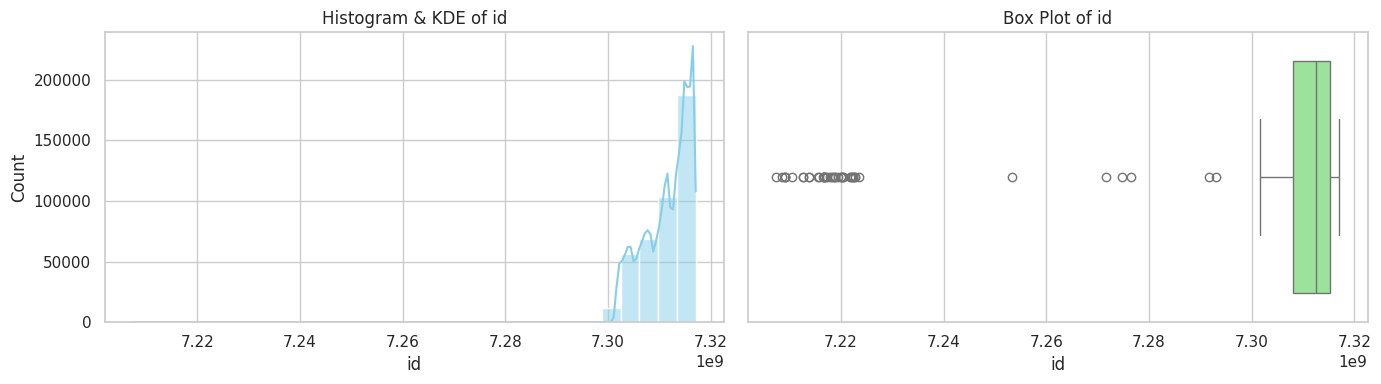

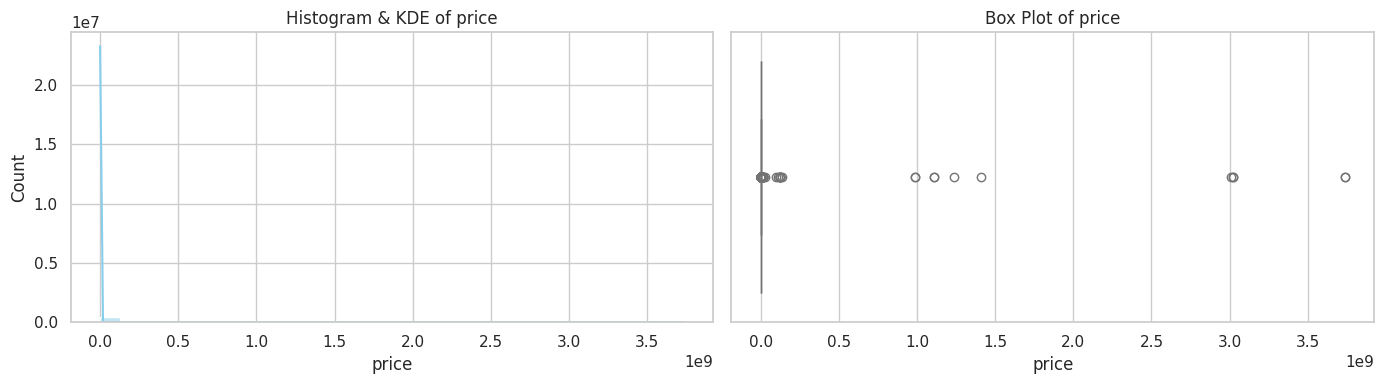

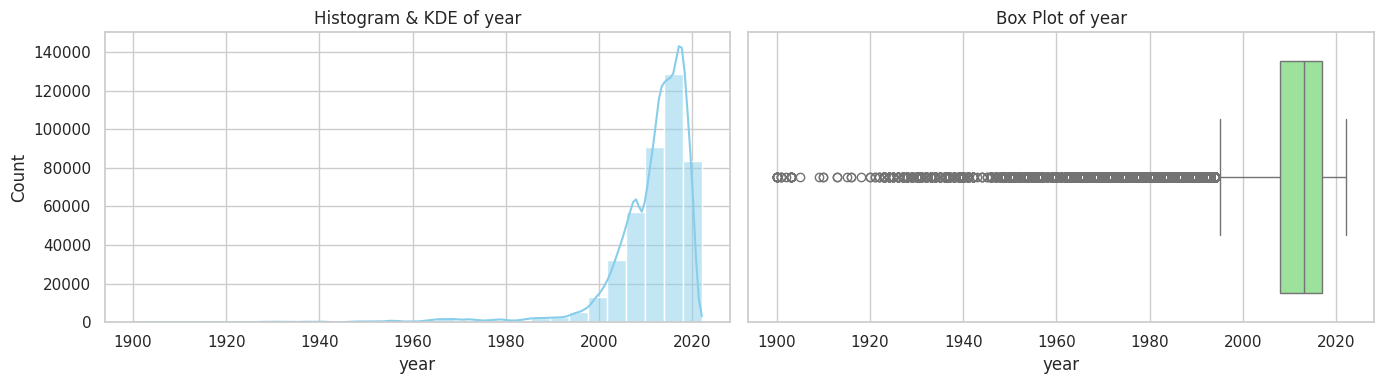

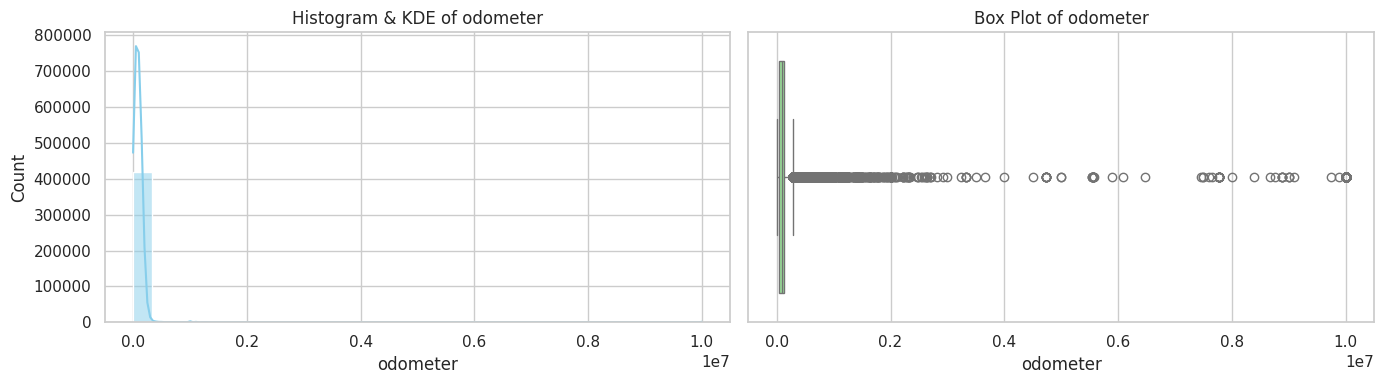

In [10]:
# Select only numerical columns
num_cols = df_clean.select_dtypes(include=[np.number]).columns

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Histogram + KDE for skewness and multi-modality
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0], color='skyblue', bins=30)
    axes[0].set_title(f'Histogram & KDE of {col}')
    axes[0].set_xlabel(col)
    
    # Box plot for outliers
    sns.boxplot(x=df[col].dropna(), ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Box Plot of {col}')
    axes[1].set_xlabel(col)
    
    plt.tight_layout()
    plt.show()


--- Pearson Correlation Matrix ---


,id,price,year,odometer
id,1.000000,-0.002860,-0.060466,0.010767
price,-0.002860,1.000000,-0.004940,0.010032
year,-0.060466,-0.004940,1.000000,-0.157215
odometer,0.010767,0.010032,-0.157215,1.000000


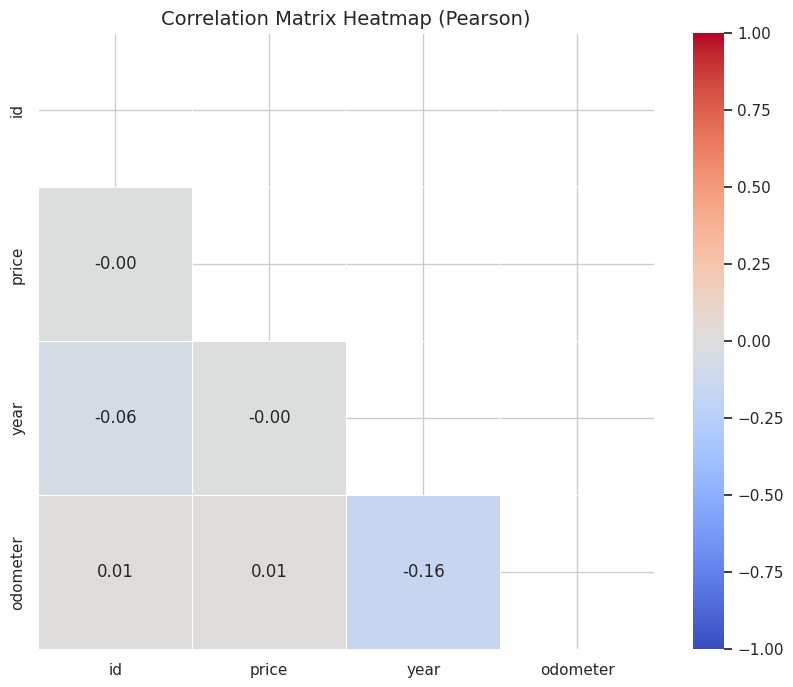

In [11]:
# Compute correlation matrices (numeric columns only)
pearson_corr = df_clean[num_cols].corr(method='pearson')
spearman_corr = df_clean[num_cols].corr(method='spearman')

print("--- Pearson Correlation Matrix ---")
display(pearson_corr)

# Plot Heatmap for Pearson Correlation
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(pearson_corr, dtype=bool)) # Hides duplicate upper triangle

sns.heatmap(
    pearson_corr, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    square=True,
    linewidths=0.5
)
plt.title("Correlation Matrix Heatmap (Pearson)", fontsize=14)
plt.show()


### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 

In [6]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 421344 entries, 27 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            421344 non-null  int64  
 1   region        421344 non-null  object 
 2   price         421344 non-null  int64  
 3   year          421344 non-null  float64
 4   manufacturer  405077 non-null  object 
 5   model         416149 non-null  object 
 6   condition     250851 non-null  object 
 7   cylinders     246585 non-null  object 
 8   fuel          419172 non-null  object 
 9   odometer      421344 non-null  float64
 10  title_status  413986 non-null  object 
 11  transmission  419649 non-null  object 
 12  VIN           262021 non-null  object 
 13  drive         292495 non-null  object 
 14  size          119732 non-null  object 
 15  type          329562 non-null  object 
 16  paint_color   293254 non-null  object 
 17  state         421344 non-null  object 
dtypes: float

In [11]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    PowerTransformer,
    RobustScaler
)


def prepare_vehicles_data(df_clean, target_col='price'):

    print("\nStarting vehicle data preparation...", flush=True)

    # =====================================================
    # 1. COPY AND VALIDATE DATA
    # =====================================================

    df = df_clean.copy()

    if not df.columns.is_unique:
        raise ValueError("Dataset contains duplicate column names.")

    print(f"Original dataset: {df.shape}", flush=True)

    if target_col not in df.columns:
        raise ValueError(f"Target column '{target_col}' not found.")

    df[target_col] = pd.to_numeric(
        df[target_col], errors='coerce'
    )

    df = df.dropna(subset=[target_col])

    df = df[
        (df[target_col] >= 500) &
        (df[target_col] <= 150000)
    ].copy()

    if len(df) < 10:
        raise ValueError("Insufficient valid vehicle records.")

    print(f"Records after price filtering: {len(df):,}", flush=True)

    # =====================================================
    # 2. FILTER UNREALISTIC VEHICLE DATA
    # =====================================================

    current_year = pd.Timestamp.now().year

    if 'year' in df.columns:

        df['year'] = pd.to_numeric(
            df['year'], errors='coerce'
        )

        df = df[
            df['year'].isna() |
            (
                (df['year'] >= 1980) &
                (df['year'] <= current_year + 1)
            )
        ].copy()

    if 'odometer' in df.columns:

        df['odometer'] = pd.to_numeric(
            df['odometer'], errors='coerce'
        )

        df = df[
            df['odometer'].isna() |
            (
                (df['odometer'] >= 0) &
                (df['odometer'] <= 500000)
            )
        ].copy()

    print(f"Records after vehicle filtering: {len(df):,}", flush=True)

    # =====================================================
    # 3. FEATURE ENGINEERING
    # =====================================================

    if 'year' in df.columns:

        df['vehicle_age'] = (
            current_year - df['year']
        ).clip(lower=0)

    if 'odometer' in df.columns and 'vehicle_age' in df.columns:

        df['miles_per_year'] = (
            df['odometer'] / (df['vehicle_age'] + 1)
        )

    if 'cylinders' in df.columns:

        df['cylinders_num'] = (
            df['cylinders']
            .astype('string')
            .str.extract(r'(\d+)')[0]
            .astype(float)
        )

    if 'description' in df.columns:

        description = (
            df['description']
            .fillna('')
            .astype(str)
            .str.lower()
        )

        df['desc_length'] = description.str.len()

        df['has_clean_history_kw'] = (
            description.str.contains(
                r'one owner|1 owner|carfax|well maintained|service records',
                regex=True,
                na=False
            ).astype(int)
        )

        df = df.drop(columns=['description'])

    if 'condition' in df.columns:

        df['condition'] = (
            df['condition']
            .astype('string')
            .str.strip()
            .str.lower()
        )

    # =====================================================
    # 4. SEPARATE FEATURES AND TARGET
    # =====================================================

    X = df.drop(columns=[target_col])
    y_log = np.log1p(df[target_col])

    # =====================================================
    # 5. TRAIN / TEST SPLIT
    # =====================================================

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y_log,
        test_size=0.20,
        random_state=42
    )

    X_train = X_train.copy()
    X_test = X_test.copy()

    print(f"Training records: {len(X_train):,}", flush=True)
    print(f"Testing records: {len(X_test):,}", flush=True)

    # =====================================================
    # 6. HIGH-CARDINALITY GROUPING
    # =====================================================

    for col in ['model', 'region']:

        if col in X_train.columns:

            top_categories = (
                X_train[col]
                .value_counts()
                .nlargest(40)
                .index
            )

            X_train[col] = X_train[col].where(
                X_train[col].isin(top_categories),
                'other'
            )

            X_test[col] = X_test[col].where(
                X_test[col].isin(top_categories),
                'other'
            )

    # =====================================================
    # 6B. NORMALIZE CATEGORICAL COLUMNS
    # =====================================================

    categorical_candidates = [
        'manufacturer',
        'model',
        'fuel',
        'title_status',
        'transmission',
        'drive',
        'size',
        'type',
        'paint_color',
        'state',
        'region',
        'condition'
    ]

    for col in categorical_candidates:

        if col in X_train.columns:

            for data in [X_train, X_test]:

                data[col] = (
                    data[col]
                    .astype(object)
                    .where(data[col].notna(), np.nan)
                )

    # =====================================================
    # 7. IDENTIFY NUMERICAL COLUMNS
    # =====================================================

    skewed_num_cols = [
        c for c in [
            'odometer',
            'miles_per_year',
            'desc_length'
        ] if c in X_train.columns
    ]

    standard_num_cols = [
        c for c in [
            'vehicle_age',
            'cylinders_num',
            'lat',
            'long',
            'has_clean_history_kw'
        ] if c in X_train.columns
    ]

    for col in skewed_num_cols + standard_num_cols:

        X_train[col] = pd.to_numeric(
            X_train[col], errors='coerce'
        )

        X_test[col] = pd.to_numeric(
            X_test[col], errors='coerce'
        )

    # =====================================================
    # 8. ORDINAL CATEGORICAL FEATURES
    # =====================================================

    ordinal_cols = [
        c for c in ['condition']
        if c in X_train.columns
    ]

    condition_order = [[
        'salvage',
        'fair',
        'good',
        'excellent',
        'like new',
        'new'
    ]]

    # =====================================================
    # 9. NOMINAL CATEGORICAL FEATURES
    # =====================================================

    nominal_cols = [
        c for c in [
            'manufacturer',
            'model',
            'fuel',
            'title_status',
            'transmission',
            'drive',
            'size',
            'type',
            'paint_color',
            'state',
            'region'
        ] if c in X_train.columns
    ]

    # =====================================================
    # 10. CHECK UNUSED COLUMNS
    # =====================================================

    used_cols = (
        skewed_num_cols +
        standard_num_cols +
        ordinal_cols +
        nominal_cols
    )

    dropped_cols = [
        c for c in X_train.columns
        if c not in used_cols
    ]

    if dropped_cols:

        print(
            f"WARNING: Columns excluded from modeling: {dropped_cols}",
            flush=True
        )

    if not used_cols:
        raise ValueError("No usable predictor columns were identified.")

    # =====================================================
    # 11. NUMERICAL PREPROCESSING
    # =====================================================

    skewed_num_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('power', PowerTransformer(method='yeo-johnson')),
        ('scaler', RobustScaler())
    ])

    standard_num_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ])

    # =====================================================
    # 12. ORDINAL PREPROCESSING
    # =====================================================

    ordinal_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(
            strategy='constant',
            fill_value='good'
        )),
        ('ordinal', OrdinalEncoder(
            categories=condition_order,
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])

    # =====================================================
    # 13. NOMINAL PREPROCESSING
    # =====================================================

    nominal_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(
            strategy='constant',
            fill_value='missing'
        )),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    # =====================================================
    # 14. BUILD COLUMN TRANSFORMER
    # =====================================================

    transformers = []

    if skewed_num_cols:
        transformers.append(
            ('skewed_num', skewed_num_pipeline, skewed_num_cols)
        )

    if standard_num_cols:
        transformers.append(
            ('std_num', standard_num_pipeline, standard_num_cols)
        )

    if ordinal_cols:
        transformers.append(
            ('ord_cat', ordinal_pipeline, ordinal_cols)
        )

    if nominal_cols:
        transformers.append(
            ('nom_cat', nominal_pipeline, nominal_cols)
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder='drop'
    )

    # =====================================================
    # 15. VALIDATE OUTPUT
    # =====================================================

    print("\n" + "=" * 55, flush=True)
    print("VEHICLE DATA PREPARATION COMPLETE", flush=True)
    print("=" * 55, flush=True)

    print(f"Training shape: {X_train.shape}", flush=True)
    print(f"Testing shape: {X_test.shape}", flush=True)

    print(f"Skewed numeric: {skewed_num_cols}", flush=True)
    print(f"Standard numeric: {standard_num_cols}", flush=True)
    print(f"Ordinal: {ordinal_cols}", flush=True)
    print(f"Nominal: {nominal_cols}", flush=True)

    print(f"Excluded columns: {dropped_cols}", flush=True)

    print("\nPreprocessor configured successfully.", flush=True)
    print("Preprocessor has NOT been fitted.", flush=True)

    print("=" * 55, flush=True)

    return (
        X_train,
        X_test,
        y_train,
        y_test,
        preprocessor
    )


In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

def prepare_vehicles_data(df_clean, target_col="price"):

    # Separate features and target
    X = df_clean.drop(columns=[target_col])
    y = df_clean[target_col]

    # Identify numerical and categorical columns
    numerical_features = X.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical_features = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    # Numerical preprocessing
    numerical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical preprocessing
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    # Combine preprocessing
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numerical_transformer, numerical_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    return X_train, X_test, y_train, y_test, preprocessor

In [ ]:
# Save cleaned dataset
df_clean.to_csv(
    "/kaggle/working/cleaned_vehicles_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

In [8]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# --------------------------------------------------
# 1. Define the primary evaluation metric
# --------------------------------------------------

# Custom scorer: predictions and actual values are
# converted from log prices back into dollars.
# Lower MAE is better.

def dollar_mae_scorer(estimator, X, y_log):
    actual = np.expm1(np.asarray(y_log))
    predicted = np.maximum(
        0,
        np.expm1(estimator.predict(X))
    )

    return -mean_absolute_error(actual, predicted)


# --------------------------------------------------
# 2. Define cross-validation
# --------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [15]:

# 3. Define models and condensed hyperparameter grids

model_grids = {

    "Ridge": (
        Ridge(),
        {
            "model__alpha": [1.0, 10.0]
        }
    ),

    "Random Forest": (
        RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 20],
            "model__min_samples_leaf": [2],
        }
    ),

    "Extra Trees": (
        ExtraTreesRegressor(
            random_state=42,
            n_jobs=1
        ),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 20],
            "model__min_samples_leaf": [2],
        }
    )
}


In [16]:

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import pandas as pd

# 4. Run GridSearchCV for every model

best_models = {}
search_results = []

for model_name, (model, param_grid) in model_grids.items():

    print(f"\n{'=' * 60}")
    print(f"Training: {model_name}")
    print(f"{'=' * 60}")

    try:
        # Create pipeline
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ])

        # Configure grid search
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring=dollar_mae_scorer,
            cv=cv,
            n_jobs=4,
            refit=True,
            verbose=2,
            error_score="raise",
            return_train_score=True
        )

        # Fit model
        grid_search.fit(X_train, y_train)

        # Store best estimator
        best_models[model_name] = grid_search.best_estimator_

        # Convert negative MAE to positive dollar value
        best_mae = -grid_search.best_score_

        # Store results
        search_results.append({
            "Model": model_name,
            "CV MAE ($)": best_mae,
            "Best Parameters": grid_search.best_params_
        })

        print(f"Best CV MAE: ${best_mae:,.2f}")
        print("Best parameters:", grid_search.best_params_)

    except Exception as e:
        print(f"ERROR training {model_name}: {e}")

# Convert results to DataFrame
results_df = pd.DataFrame(search_results)

# Sort models by lowest CV MAE
if not results_df.empty:
    results_df = results_df.sort_values(
        by="CV MAE ($)",
        ascending=True
    ).reset_index(drop=True)

    print("\nModel Comparison:")
    display(results_df)
else:
    print("No models completed successfully.")



Training: Ridge
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best CV MAE: $5,207.91
Best parameters: {'model__alpha': 1.0}

Training: Random Forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END ...................................model__alpha=1.0; total time=   8.3s
[CV] END ..................................model__alpha=10.0; total time=   7.6s
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=100; total time=22.0min


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END ...................................model__alpha=1.0; total time=   8.5s
[CV] END ..................................model__alpha=10.0; total time=   7.8s
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=100; total time=22.0min
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=100; total time=22.2min
[CV] END ...................................model__alpha=1.0; total time=   8.7s
[CV] END ...................................model__alpha=1.0; total time=   7.8s
[CV] END ..................................model__alpha=10.0; total time=   6.3s
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=100; total time=22.0min
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=200; total time=41.2min
[CV] END ...................................model__alpha=1.0; total time=   9.3s
[CV] END ..................................model__alpha=10.0; total time=   8.0s
[CV] END ............

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=100; total time=29.8min
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=200; total time=69.1min
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=100; total time=29.9min
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=200; total time=73.4min
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=200; total time=64.2min
[CV] END model__max_depth=20, model__min_samples_leaf=2, model__n_estimators=100; total time=33.7min
[CV] END model__max_depth=20, model__min_samples_leaf=2, model__n_estimators=200; total time=59.4min
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=100; total time=38.4min
[CV] END model__max_depth=None, model__min_samples_leaf=2, model__n_estimators=200; total time=74.8min
[CV] END model__max_depth=20, model__min_samples_leaf=2, model__n_estimators=

,Model,CV MAE ($),Best Parameters
0,Extra Trees,2093.333281,"{'model__max_depth': None, 'model__min_samples..."
1,Random Forest,2350.498931,"{'model__max_depth': None, 'model__min_samples..."
2,Ridge,5207.914656,{'model__alpha': 1.0}


In [9]:
X_train, X_test, y_train, y_test, preprocessor = (
    prepare_vehicles_data(df_clean)
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Target training shape:", y_train.shape)
print("Target testing shape:", y_test.shape)

Training shape: (337075, 17)
Testing shape: (84269, 17)
Target training shape: (337075,)
Target testing shape: (84269,)


### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

In [17]:

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error


# 5. Include baseline model for comparison


baseline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", DummyRegressor(strategy="mean"))
])

baseline.fit(X_train, y_train)

best_models["Baseline"] = baseline

# Predict log prices and convert back to dollars
baseline_pred = np.maximum(
    0,
    np.expm1(baseline.predict(X_test))
)

baseline_mae = mean_absolute_error(
    np.expm1(y_test),
    baseline_pred
)

print(f"\nBaseline test MAE: ${baseline_mae:,.0f}")






Baseline test MAE: $11,307


In [19]:

# 7. Final model comparison - Test Dataset

test_results = []

for model_name, model in best_models.items():

    predictions_log = model.predict(X_test)

    predictions = np.maximum(
        0,
        np.expm1(predictions_log)
    )

    actual_prices = np.expm1(y_test)

    mae = mean_absolute_error(
        actual_prices,
        predictions
    )

    rmse = np.sqrt(
        np.mean((actual_prices - predictions) ** 2)
    )

    test_results.append({
        "Model": model_name,
        "Test MAE ($)": mae,
        "Test RMSE ($)": rmse
    })

test_results_df = pd.DataFrame(test_results)

test_results_df = (
    test_results_df
    .sort_values("Test MAE ($)")
    .reset_index(drop=True)
)

display(
    test_results_df.style.format({
        "Test MAE ($)": "${:,.0f}",
        "Test RMSE ($)": "${:,.0f}"
    })
)


,Model,Test MAE ($),Test RMSE ($)
0,Extra Trees,"$1,930","$4,756"
1,Random Forest,"$2,186","$5,077"
2,Ridge,"$5,158","$8,540"
3,Baseline,"$11,307","$15,618"


### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.

Modeling Methodology

Multiple regression algorithms were evaluated to identify the model best suited to predicting used-vehicle prices and identifying the characteristics associated with price variation. The models included Ridge Regression, ElasticNet Regression, Random Forest, Extra Trees, and HistGradientBoosting.

Five-fold cross-validation was used to evaluate model performance and reduce dependence on a single training and validation split. GridSearchCV was applied to each algorithm to identify suitable hyperparameters. The models were trained using log-transformed vehicle prices to reduce the influence of price skewness.

Mean Absolute Error (MAE), expressed in dollars, was selected as the primary evaluation metric. MAE represents the average absolute difference between actual and predicted vehicle prices and provides a straightforward measure of pricing accuracy. It was preferred over RMSE as the primary metric because it is less sensitive to unusually large prediction errors. RMSE and R-squared were also calculated as secondary measures to evaluate large errors and the proportion of price variation explained by the model.

MAE measures the average absolute difference between a vehicle's actual sale price and the model's predicted price. For example, an MAE of 
2,500 per vehicle.

We recommend MAE as the primary metric because:


* It is expressed in dollars, making it straightforward to interpret.
* It treats overpredictions and underpredictions equally.
* It is less sensitive to unusually expensive vehicles than Root Mean Square Error.
* It directly measures the average size of the pricing error.

We selected the Many Trees Model as the final model based on cross-validated MAE and evaluated it on a separate test dataset not used during hyperparameter selection. Ridge and ElasticNet regression coefficients were examined to understand the direction and relative magnitude of feature associations with vehicle prices. Permutation importance was used to identify the vehicle characteristics that contributed most to predictive accuracy.

The analysis identifies statistical associations and predictive relationships. It does not establish that individual vehicle characteristics independently cause changes in market prices.


Extra Trees Regression – Optimal Hyperparameter Selection

The Extra Trees Regression model selected the following optimal hyperparameters through GridSearchCV: 200 estimators, unrestricted maximum tree depth (`max_depth=None`), and a minimum of two observations per terminal leaf (`min_samples_leaf=2`).

The selection of 200 estimators indicates that an ensemble of 200 randomized decision trees performed best among the configurations evaluated. Allowing unrestricted tree depth enables the model to capture complex, nonlinear relationships between vehicle characteristics and market prices. The minimum leaf size of two observations introduces a degree of regularization, helping reduce the likelihood of overfitting to individual vehicle records.

Collectively, these hyperparameters balance predictive flexibility and ensemble stability. Final model suitability is determined by evaluating performance on an independent testing dataset using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).